# Coordinazione locale ed energia di Lennard-Jones nell'argento FCC

## Obiettivo

Partendo dalle coordinate di un cristallo FCC di argento, questo notebook mostra come:

1. identificare la **prima shell di coordinazione** di un atomo (distanze e numero di vicini);
2. stimare il **parametro reticolare FCC**;
3. costruire una **lista dei vicini** entro un cutoff $r_c$;
4. calcolare l'**energia potenziale di Lennard-Jones**.

<div style="background:#e3f2fd; border-left:6px solid #2196f3; padding:12px 16px; border-radius:6px;">
<p><b>Nota (modello).</b> L'argento è davvero <b>FCC</b> (<code>Fm-3m</code>, a ≈ 4.09 Å). Il potenziale di Lennard-Jones però nasce per i <b>gas nobili</b> (interazione a 2 corpi, van der Waals); per un metallo come Ag il legame è <b>molti-corpi</b>, quindi LJ sbaglia scala e proprietà (energia di coesione, elasticità, superfici). Qui va inteso come <b>esercizio didattico</b>: il modello realistico sarebbe EAM o DFT.</p>
</div>

## Prerequisiti

- Python 3.12 o superiore
- Package: `numpy`, `ovito`, `ipywidgets`
- Concetto di distanza interatomica e di raggio di cutoff

## 1. Configurazione

Parametri modificabili per l'analisi.

In [27]:
FILENAME = "fcc100a108.txt"  # 108 atomi, lastra FCC(100) di Ag
REFERENCE_ATOM = 19  # atomo interno (bulk): attesi 12 primi vicini

R_MIN, R_MAX = 2.0, 3.0  # intervallo della prima shell di coordinazione [Å]
RC = 3.0  # cutoff della lista dei vicini [Å]

SIGMA = 2.644  # parametro Lennard-Jones per Ag [Å]
EPSILON = 0.345  # profondità della buca Lennard-Jones per Ag [eV]

BACKGROUND_RADIUS_SCALE = 0.38  # scala del raggio degli atomi di contesto
BACKGROUND_TRANSPARENCY = (
    0.85  # trasparenza degli atomi di contesto (0=opaco, 1=trasparente)
)

# Viste da bloccare (lista di 4 camere da viewport_cameras()).
# None = inquadratura automatica; incolla qui la lista per fissare le viste nel libro.
CAMERAS = None

## 2. Setup e dipendenze

**IMPORTANTE**: la cella seguente aggiunge automaticamente `src/` al path Python,
poi importa le utility del package `computational_course`.

In [28]:
import sys
from pathlib import Path


def _setup_path():
    root = Path.cwd()
    for _ in range(10):
        if (root / "pyproject.toml").exists():
            break
        root = root.parent
    src_path = str(root / "src")
    if src_path not in sys.path:
        sys.path.insert(0, src_path)
    return root


PROJECT_ROOT = _setup_path()

import numpy as np
import ovito
from IPython.display import Image

from computational_course.lennard_jones import (
    build_neighbor_list,
    lennard_jones_energy,
)
from computational_course.ovito_visualization import (
    compute_neighbor_distances,
    convert_to_xyz,
    create_ovito_pipeline,
    create_viewport_grid,
    load_structure,
    print_analysis_report,
    render_viewport_grid,
    viewport_cameras,
)

print(f"Project root: {PROJECT_ROOT}")
print("Import completato.")

Project root: /Users/francesco/dev/computational-course
Import completato.


## 3. Caricamento della struttura

In [29]:
txt_path, coords = load_structure(FILENAME, PROJECT_ROOT)
natoms = len(coords)

print(f"File: {txt_path.name}")
print(f"Atomi: {natoms}")
print(f"Shape coordinate: {coords.shape}")

File: fcc100a108.txt
Atomi: 108
Shape coordinate: (108, 3)


## 4. Coordinazione locale

In un cristallo FCC la distanza tra primi vicini è $d_{nn} = a / \sqrt{2}$.
Contando gli atomi tra $R_{min}$ e $R_{max}$ otteniamo il **numero di coordinazione**
e, invertendo la relazione, il **parametro reticolare** $a = \sqrt{2}\,d_{nn}$.

In [30]:
results = compute_neighbor_distances(coords, REFERENCE_ATOM, R_MIN, R_MAX)

reference_index = REFERENCE_ATOM - 1
reference_position = coords[reference_index]

neighbor_mask = np.zeros(natoms, dtype=bool)
neighbor_mask[results["neighbor_indices"]] = True

print_analysis_report(
    REFERENCE_ATOM, reference_position, R_MIN, R_MAX, results, max_print=12
)

 ANALISI GEOMETRICA LOCALE

Atomo di riferimento : 19
Posizione [Å]        : (6.2406, 4.1604, 2.0802)
Intervallo           : 2.00 < d < 3.00 Å
Numero di vicini     : 12
Ambiente locale      : FCC bulk
d_nn                 : 2.9418 Å
R geometrico FCC     : 1.4709 Å
a FCC stimato        : 4.1604 Å

Primi vicini:
  Atom     8
  Atom     9
  Atom    10
  Atom    15
  Atom    20
  Atom    28
  Atom    30
  Atom    32
  Atom    43
  Atom    44
  Atom    47
  Atom    50


## 5. Visualizzazione con OVITO

Creiamo una pipeline OVITO con atomi colorati in base alla loro coordinazione:

- **Giallo**: atomo di riferimento
- **Rosso**: primi vicini (distanza tra $R_{min}$ e $R_{max}$)
- **Grigio chiaro**: atomi di contesto (ridotti e semitrasparenti)

In [31]:
xyz_path = convert_to_xyz(coords, txt_path.stem, element="Ag")
print(f"File XYZ creato: {xyz_path}")

File XYZ creato: generated/fcc100a108.xyz


In [32]:
pipeline = create_ovito_pipeline(
    xyz_path,
    coords,
    neighbor_mask,
    reference_index,
    results["atomic_radius"],
    background_radius_scale=BACKGROUND_RADIUS_SCALE,
    background_transparency=BACKGROUND_TRANSPARENCY,
)

for old_pipeline in list(ovito.scene.pipelines):
    old_pipeline.remove_from_scene()

pipeline.add_to_scene()
print("Pipeline OVITO creata e aggiunta alla scena.")

Pipeline OVITO creata e aggiunta alla scena.


In [33]:
grid, viewports = create_viewport_grid(R_MIN, R_MAX, REFERENCE_ATOM, cameras=CAMERAS)
grid

GridBox(children=(VBox(children=(HTML(value='\n        <div style="\n            background:#202225;\n        …

### Bloccare la vista scelta (freezenig per jupyterbook)

Ruota e zooma le quattro viste qui sopra come preferisci. Poi esegui la cella
seguente: stampa la configurazione corrente delle camere. Incollala in
`CAMERAS` (cella di configurazione) e riesegui il notebook. Il libro, che non
ha interazione, ricostruirà esattamente quelle viste.

In [41]:
CAMERA = viewport_cameras(viewports)

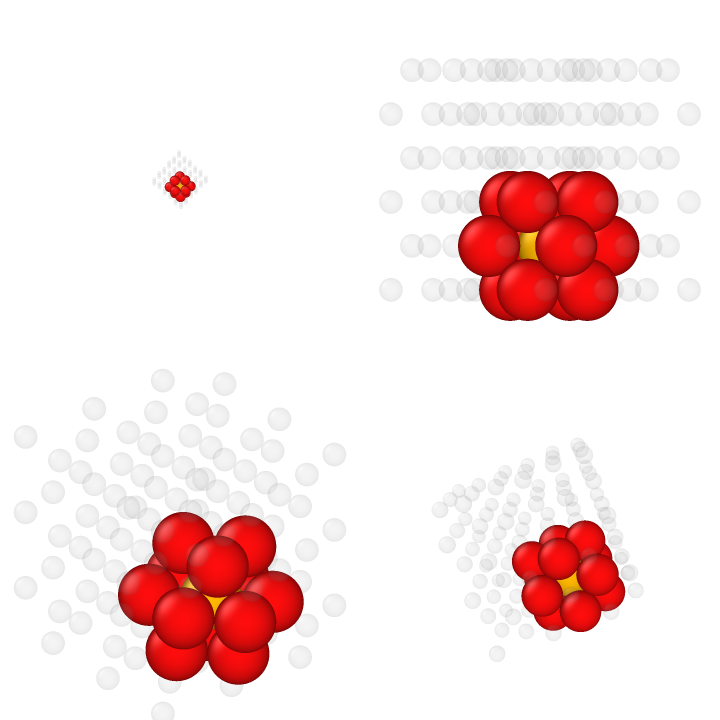

In [42]:
grid_png = render_viewport_grid(
    viewports, PROJECT_ROOT / "figures" / "coordinazione_grid.png"
)
Image(filename=str(grid_png))

**Legenda dei quattro pannelli** (griglia 2×2, ordine di lettura):

| Posizione | Pannello | Piano | Come si legge |
| --- | --- | --- | --- |
| alto-sinistra | Top | **XY** | guardi lungo l'asse $z$ |
| alto-destra | Front | **XZ** | guardi lungo l'asse $y$ |
| basso-sinistra | Left | **YZ** | guardi lungo l'asse $x$ |
| basso-destra | Perspective | **XYZ** | vista 3D, nessun piano |

Nella vista **Perspective** i 12 primi vicini (rossi) attorno all'atomo centrale (giallo)
formano un **cubottaedro**: è la firma geometrica della prima shell FCC.

## 6. Lista dei vicini entro il cutoff

Un calcolo ingenuo dell'energia confronta **tutte** le coppie: costo $O(N^2)$.
Conviene separare la **ricerca dei vicini** dal **calcolo dell'interazione**:
si costruisce una lista dei vicini entro $r_c$ e poi si somma il potenziale solo su quelle coppie.

Costruiamo prima la lista a mano per vedere il meccanismo, poi usiamo la funzione del package.

In [36]:
nnbrs = np.zeros(natoms, dtype=int)
whichnbr = np.zeros((natoms, natoms), dtype=int)

for i in range(natoms):
    for j in range(natoms):
        if i != j and np.linalg.norm(coords[i] - coords[j]) < RC:
            whichnbr[i, nnbrs[i]] = j  # j va nel prossimo slot libero della riga i
            nnbrs[i] += 1  # il contatore diventa l'indice dello slot successivo

print("Vicini per atomo (primi 12):", nnbrs[:12])
print(f"Coordinazione media: {nnbrs.mean():.2f}")

Vicini per atomo (primi 12): [8 3 5 8 5 5 5 8 8 8 8 5]
Coordinazione media: 8.33


In [37]:
nnbrs_ref, whichnbr_ref = build_neighbor_list(coords, RC)
assert (nnbrs_ref == nnbrs).all()
print("La funzione del package riproduce la lista scritta a mano.")

La funzione del package riproduce la lista scritta a mano.


### Come leggere `nnbrs` e `whichnbr`

**Cosa sono.** Sono i due array che descrivono la lista dei vicini, cioè quali atomi
stanno entro $r_c$ per ciascun atomo:

- `nnbrs[i]` (intero) = **quanti** vicini ha l'atomo `i`;
- `whichnbr[i, k]` = **indice** del $k$-esimo vicino dell'atomo `i`.

**Come si usano.** Si costruiscono insieme, in un solo passaggio:

```python
whichnbr[i, nnbrs[i]] = j   # scrivi j nel prossimo slot libero della riga i
nnbrs[i] += 1               # avanza il contatore
```

`nnbrs[i]` fa **due lavori**: è il contatore dei vicini già trovati e, insieme,
l'indice del prossimo slot libero. Di ogni riga `whichnbr[i]` sono quindi validi
**solo** i primi `nnbrs[i]` elementi:

```python
vicini_di_i = whichnbr[i, :nnbrs[i]]   # indici reali dei vicini
```

Gli zeri a destra (da `np.zeros`) sono solo riempimento: **non** significano
"vicino = atomo 0".

**Esempio.** Mettiamo i due array in una tabella (una riga per atomo), con `<NA>`
dove la riga non ha più vicini:

In [38]:
import pandas as pd

n_show = 108
righe = {
    f"vicino {k}": [
        whichnbr_ref[i, k] if k < nnbrs_ref[i] else pd.NA for i in range(n_show)
    ]
    for k in range(int(nnbrs_ref[:n_show].max()))
}
table = pd.DataFrame({"nnbrs": nnbrs_ref[:n_show], **righe})
table.index.name = "atomo"
table

,nnbrs,vicino 0,vicino 1,vicino 2,vicino 3,vicino 4,vicino 5,vicino 6,vicino 7,vicino 8,vicino 9,vicino 10,vicino 11
atomo,,,,,,,,,,,,,
0,8,1,2,6,8,24,29,32,33,<NA>,<NA>,<NA>,<NA>
1,3,0,32,33,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
2,5,0,3,24,25,32,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
3,8,2,4,8,10,19,20,24,25,<NA>,<NA>,<NA>,<NA>
4,5,3,5,20,21,25,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
...,...,...,...,...,...,...,...,...,...,...,...,...,...
103,5,76,77,80,92,102,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
104,5,82,83,86,91,105,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>
105,5,76,82,83,102,104,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>


**A cosa servono, e come evolvono in MD.**

- **Calcolo statico.** Separano la *ricerca dei vicini* dal *calcolo dell'energia*:
  si somma $\varphi(r_{ij})$ solo sulle coppie in lista, invece di confrontare
  tutte le $N^2$ coppie.
- **In dinamica molecolare.** Servono anche per le **forze**, che si calcolano solo
  tra vicini: $\vec F_i = -\sum_{j} \frac{d\varphi}{dr}\,\hat r_{ij}$. Il costo per passo
  diventa proporzionale al numero di vicini, non a $N^2$.
- **Come evolve.** In MD gli atomi si muovono e i vicini **cambiano**: la lista va
  **ricostruita** o **aggiornata**. La tecnica standard è lo **skin**: si usa un raggio
  $r_c + \delta$ e si riusa la lista finché nessun atomo si è spostato di più di
  $\delta/2$; solo allora la si ricostruisce (lista di Verlet, cell list).

<div style="background:#fff3b0; border-left:6px solid #e6b800; padding:12px 16px; border-radius:6px;">
<p><b>Nota.</b> Chi ha <b>più</b> primi vicini dà un contributo <b>maggiore</b> all'energia di interazione; chi ne ha <b>pochi</b> (di solito quelli alla <b>periferia del bulk</b>) contribuisce meno. In dinamica questi ultimi si muoveranno <b>di più</b> (meno legati) e possono persino <b>staccarsi dal bulk</b>. Gli atomi <b>centrali</b>, con molti vicini, sono invece <b>meno dinamici</b>.</p>
</div>

## 7. Energia di Lennard-Jones con cutoff

Il potenziale a coppie è

$$\varphi(r) = 4\varepsilon\left[\left(\frac{\sigma}{r}\right)^{12} - \left(\frac{\sigma}{r}\right)^{6}\right]$$

e l'energia potenziale totale, sommata su tutte le coppie entro $r_c$ con fattore $1/2$
per il doppio conteggio, è

$$E_{pot} = \sum_i \sum_{j \in \text{vicini}(i)} \tfrac12\,\varphi(r_{ij}).$$

Nota: con $r_c = 3.0$ Å oppure $r_c = 4.0$ Å si ottiene la **stessa** energia,
perché la seconda shell cade a $a = 4.16$ Å e resta fuori dal cutoff in entrambi i casi.

In [39]:
epot = lennard_jones_energy(coords, SIGMA, EPSILON, nnbrs_ref, whichnbr_ref)

print(f"Energia potenziale (rc = {RC} Å): {epot:.6f} eV")
print(f"Numero medio di vicini          : {nnbrs_ref.mean():.2f}")

Energia potenziale (rc = 3.0 Å): -154.795762 eV
Numero medio di vicini          : 8.33


### Controllo di coerenza (versione vettoriale)

Ricalcoliamo la stessa energia con una matrice di distanze $d_{ij}$ e una maschera
booleana per il cutoff: il risultato deve coincidere con quello della lista dei vicini.

In [40]:
d = np.linalg.norm(coords[:, None, :] - coords[None, :, :], axis=-1)
mask = (d < RC) & ~np.eye(natoms, dtype=bool)
sr6 = (SIGMA / d[mask]) ** 6
epot_vec = 0.5 * np.sum(4 * EPSILON * (sr6**2 - sr6))

print(f"Verifica vettoriale: {epot_vec:.6f} eV")
assert np.isclose(epot, epot_vec)

Verifica vettoriale: -154.795762 eV


## 8. Riepilogo

### Cosa abbiamo imparato

1. La prima shell FCC contiene **12** vicini a $d_{nn} = a/\sqrt{2}$; superficie e spigoli
   hanno coordinazione minore (8, 5, ...).
2. Stimando $a = \sqrt{2}\,d_{nn}$ si ritrova $a \approx 4.16$ Å per l'argento.
3. La **lista dei vicini** (`nnbrs`, `whichnbr`) separa la ricerca dei vicini dal calcolo dell'energia.
4. Con $r_c = 3.0$ Å il potenziale di Lennard-Jones dà $E_{pot} \approx -154.80$ eV.

### Limiti

- Costo $O(N^2)$: adatto a sistemi piccoli.
- Nessuna **condizione periodica al contorno** (PBC): si usano le distanze dirette.
- Cutoff **troncato** (nessuno shift a $r_c$), quindi $E_{pot}$ dipende dalla scelta di $r_c$.

### Estensioni

- Distribuzione dei numeri di coordinazione su tutti gli atomi.
- Confronto tra Lennard-Jones e potenziali più realistici (es. EAM) per l'argento.
- **Nella dinamica i vicini cambiano:** la lista va aggiornata durante la simulazione.